In [3]:
# Import the necessary packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Scikit-learn tools for modeling
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [4]:
# Read in our cafe dataset - remember it has to be loaded into Colab environment
cafe_sales = pd.read_csv("cafe_data.csv")
cafe_sales.head()

,Transaction ID,Item,Quantity,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,4.0,Credit Card,Takeaway,9/8/2023
1,TXN_4977031,Cake,4,12.0,Cash,In-store,5/16/2023
2,TXN_4271903,Cookie,4,4.0,Credit Card,In-store,7/19/2023
3,TXN_7034554,Salad,2,10.0,Unknown,Unknown,4/27/2023
4,TXN_3160411,Coffee,2,4.0,Digital Wallet,In-store,6/11/2023


# Preparing Data for Modeling
We will reuse the ideas from our feature engineering notebook since this notebook needs to run on its own.

In this notebook, our target variable (the thing we want to predict) is **Total Spent**. Everything else we choose to keep will be a feature (a variable used to make the prediction).

*Transaction ID is just a unique label, so it has no predictive value and we leave it out.

In [5]:
# Convert Transaction Date to a datetime
cafe_sales["Transaction Date"] = pd.to_datetime(cafe_sales["Transaction Date"])

# Check how many dates are missing
print(cafe_sales["Transaction Date"].isna().sum())

334


In [6]:
# The simplest way to handle the missing dates is to drop those rows
# (Other options, like imputing, are worth considering on a real project)
cafe_sales = cafe_sales.dropna(subset=["Transaction Date"])

# Feature splitting: pull a Month and a Weekend/Weekday variable from the date
cafe_sales["Month"] = cafe_sales["Transaction Date"].dt.month
cafe_sales["Is Weekend"] = cafe_sales["Transaction Date"].dt.dayofweek.isin([5, 6]).astype(int)

cafe_sales.head()

,Transaction ID,Item,Quantity,Total Spent,Payment Method,Location,Transaction Date,Month,Is Weekend
0,TXN_1961373,Coffee,2,4.0,Credit Card,Takeaway,2023-09-08,9,0
1,TXN_4977031,Cake,4,12.0,Cash,In-store,2023-05-16,5,0
2,TXN_4271903,Cookie,4,4.0,Credit Card,In-store,2023-07-19,7,0
3,TXN_7034554,Salad,2,10.0,Unknown,Unknown,2023-04-27,4,0
4,TXN_3160411,Coffee,2,4.0,Digital Wallet,In-store,2023-06-11,6,1


## One-Hot Encoding for Modeling
We'll one-hot encode our categorical variables just like before. We must make sure to drop one of the column to avoid perfect prediction of the other. We will use drop_first=True to accomplish this

In [7]:
# Select our features and target
features = ["Quantity", "Item", "Payment Method", "Location", "Month", "Is Weekend"]
X = cafe_sales[features]
y = cafe_sales["Total Spent"]

# One-hot encode the categorical features, dropping the first category of each
X = pd.get_dummies(X, columns=["Item", "Payment Method", "Location"], drop_first=True, dtype=int)
X.head()

,Quantity,Month,Is Weekend,Item_Coffee,Item_Cookie,Item_Juice,Item_Salad,Item_Sandwich,Item_Smoothie,Item_Tea,Item_Unknown,Payment Method_Credit Card,Payment Method_Digital Wallet,Payment Method_Unknown,Location_Takeaway,Location_Unknown
0,2,9,0,1,0,0,0,0,0,0,0,1,0,0,1,0
1,4,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,4,7,0,0,1,0,0,0,0,0,0,1,0,0,0,0
3,2,4,0,0,0,0,1,0,0,0,0,0,0,1,0,1
4,2,6,1,1,0,0,0,0,0,0,0,0,1,0,0,0


# Train/Test Split
- Training set: the data the model learns from
- Test set: data the model has never seen, used to measure performance

**train_test_split()** randomly divides our data for us. We use test_size=0.2 to hold out 20% for testing, and random_state so that we get the same split every time we run the code (to make sure you are doing things right).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)

(7321, 16)
(1831, 16)


# Evaluating Models
We'll use three metrics to evaluate our models:

- R²: the proportion of the variation in the target that the model explains. 1 is perfect, and 0 is no better than always guessing the average.
- RMSE (Root Mean Squared Error): the typical size of the model's errors, in the same units as the target (dollars, for us). It penalizes large errors more heavily.
- MAE (Mean Absolute Error): the average size of the model's errors, also in dollars.

We'll compare Train R² with Test R². If a model's Train R² is much higher than its Test R², it is overfitting, meaning it memorized the training data instead of learning patterns that generalize.

The function below will help evaluate each model in the same way

In [9]:
# Store the results of each model so we can compare them at the end
results = []

def evaluate_model(name, model, X_tr, X_te):
    # Predict on the test set
    preds = model.predict(X_te)

    # Calculate each metric and save it
    results.append({
        "Model": name,
        "Train R2": model.score(X_tr, y_train),
        "Test R2": r2_score(y_test, preds),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, preds)),
        "Test MAE": mean_absolute_error(y_test, preds)
    })
    return preds

# Multiple Linear Regression
Multiple linear regression predicts the target using a weighted sum of the features:

**Total Spent = intercept + (coef₁ × feature₁) + (coef₂ × feature₂) + ...**

The model finds the intercept and coefficients that minimize the squared errors on the training data. Each coefficient tells us how much the prediction changes when that feature goes up by one unit, holding all of the other features constant.

The modeling process in scikit-learn is always the same:
1. Create the model
2. .fit() it on the training data
3. .predict() on new data
4. Evaluate the predictions

In [10]:
# Create and fit the model
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# Predict and evaluate
lin_preds = evaluate_model("Linear Regression", lin_reg, X_train, X_test)
pd.DataFrame(results)

,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Linear Regression,0.875749,0.874449,2.139939,1.461397


## Actual vs. Predicted
A great way to check a model visually is to plot the actual values against the predictions. A perfect model would have every point on the red line.

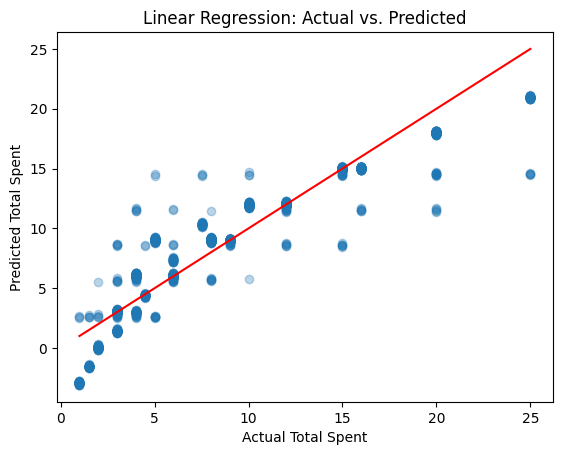

In [11]:
plt.scatter(y_test, lin_preds, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")
plt.title("Linear Regression: Actual vs. Predicted")
plt.xlabel("Actual Total Spent")
plt.ylabel("Predicted Total Spent")
plt.show()

# Regularization: Ridge and Lasso Regression

- Ridge Regression (L2) penalizes the squared size of the coefficients.
- Lasso Regression (L1) penalizes the absolute size of the coefficients.

Both models have a hyperparameter called alpha that controls the strength of the penalty:
- alpha = 0 is the same as ordinary linear regression
- Larger alpha means a stronger penalty and a simpler model

## Scaling
Without scaling, a feature measured in large numbers would get a small coefficient and barely be penalized, while a feature measured in small numbers would be penalized heavily.

StandardScaler rescales each feature to have a mean of 0 and standard deviation of 1.

Important: fit the scaler on the training data only, then use it to transform both sets. Fitting on the test data would leak information about the test set into our model.

In [12]:
scaler = StandardScaler()

# fit_transform on the training data, transform only on the test data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Ridge Regression
Let's start with a fixed alpha of 1 to see how it works.

In [13]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

ridge_preds = evaluate_model("Ridge (alpha=1)", ridge, X_train_scaled, X_test_scaled)
pd.DataFrame(results)

,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Linear Regression,0.875749,0.874449,2.139939,1.461397
1,Ridge (alpha=1),0.875749,0.874450,2.139929,1.461406


## Lasso Regression
Now the same with Lasso, again using alpha = 1.

In [14]:
lasso = Lasso(alpha=1.0)
lasso.fit(X_train_scaled, y_train)

lasso_preds = evaluate_model("Lasso (alpha=1)", lasso, X_train_scaled, X_test_scaled)
pd.DataFrame(results)

,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Linear Regression,0.875749,0.874449,2.139939,1.461397
1,Ridge (alpha=1),0.875749,0.874450,2.139929,1.461406
2,Lasso (alpha=1),0.700202,0.704496,3.283014,2.580320


# Random Forest Regression
Each tree is trained on a random sample of the rows and considers a random subset of features at each split. To make a prediction, the forest averages the predictions of all of its trees.

Compared to linear regression:
- It can capture non-linear relationships and interactions between features automatically
- It does not require scaling
- It is much harder to interpret, since there are no simple coefficients
- It can overfit if the trees are allowed to grow too deep

Key hyperparameters:
- **n_estimators**: the number of trees in the forest
- **max_depth**: the maximum depth of each tree
- **min_samples_leaf**: the minimum number of data points allowed in a leaf, which stops trees from memorizing tiny groups

In [15]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)

# No scaling needed for tree-based models, so we use the unscaled data
rf.fit(X_train, y_train)

rf_preds = evaluate_model("Random Forest", rf, X_train, X_test)
pd.DataFrame(results)

,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Linear Regression,0.875749,0.874449,2.139939,1.461397
1,Ridge (alpha=1),0.875749,0.874450,2.139929,1.461406
2,Lasso (alpha=1),0.700202,0.704496,3.283014,2.580320
3,Random Forest,0.987320,0.948791,1.366676,0.301921


## Feature Importance
Random forests do not have coefficients, but they do tell us how much each feature contributed to reducing the model's error across all of the trees. These importances add up to 1.

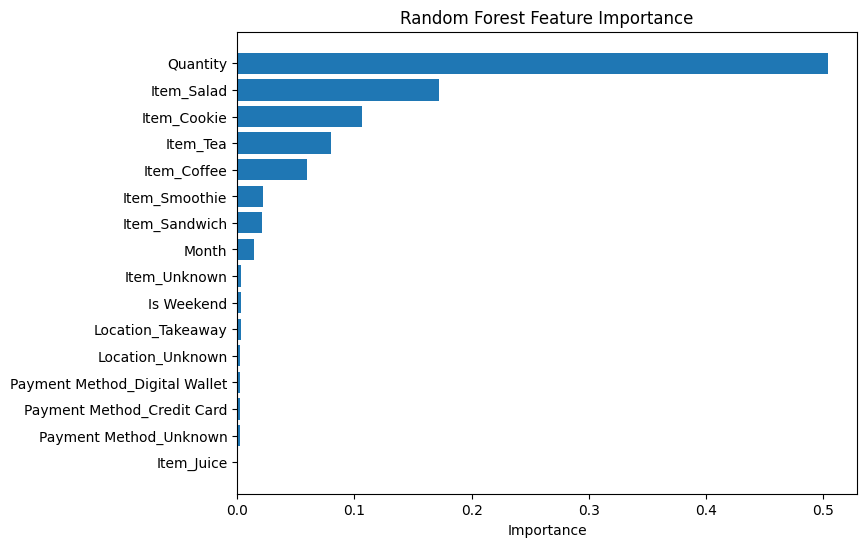

In [16]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importances.index, importances)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

## Limiting Tree Depth
Let's see how max_depth affects the model. A very shallow forest can't learn enough (underfitting), and a very deep forest can memorize the training data (overfitting). Comparing Train R² and Test R² across depths shows the tradeoff.

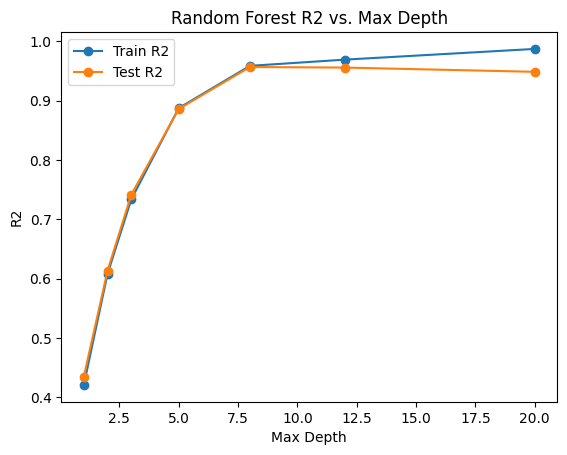

In [17]:
depths = [1, 2, 3, 5, 8, 12, 20]
train_scores = []
test_scores = []

for d in depths:
    model = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

plt.plot(depths, train_scores, marker="o", label="Train R2")
plt.plot(depths, test_scores, marker="o", label="Test R2")
plt.title("Random Forest R2 vs. Max Depth")
plt.xlabel("Max Depth")
plt.ylabel("R2")
plt.legend()
plt.show()